### Step 1
Use the data from ```data/subset_homework.pckl``` (or the ```data/subset_homework``` folder) and visualize some examples. How many images are there for each class?

In [1]:
import os
os.environ['KERAS_BACKEND'] = 'torch'

import pickle
from time import time
import numpy as np
from sklearn.utils import shuffle

from matplotlib import pyplot as plt
plt.rcParams['figure.figsize'] = [15, 6]

In [2]:
with open('../data/subset_homework.pckl', 'rb') as f:
    data = pickle.load(f)

images_0 = data['class_id_0']
images_1 = data['class_id_1']
labels_0 = [0] * len(images_0)
labels_1 = [1] * len(images_1)

print('Image shape ', images_0[0].shape, images_0[0].dtype)

Image shape  (28, 28) uint8


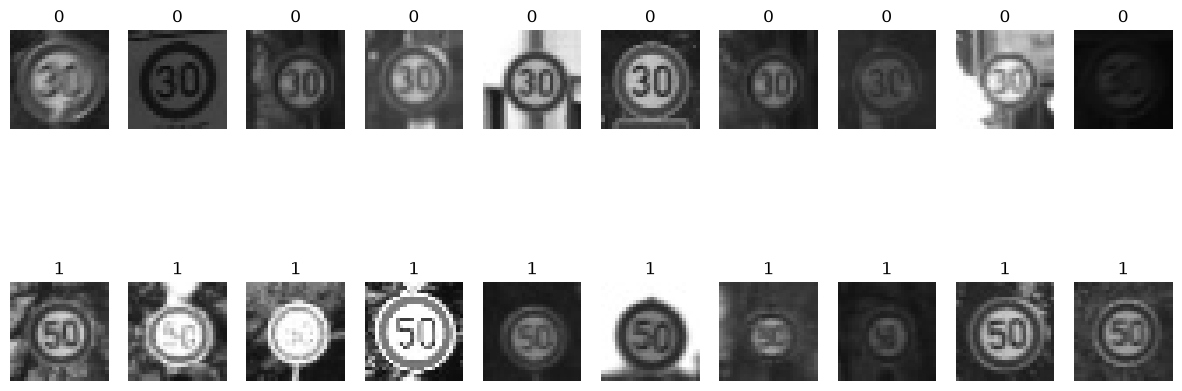

In [3]:
for row, (images, labels) in enumerate([(images_0, labels_0), (images_1, labels_1)]):
    for cnt, idx in enumerate(np.random.randint(0, len(images), 10)):
        plt.subplot(2, 10, row * 10 + cnt + 1)
        plt.imshow(images[idx], cmap='gray', vmin=0, vmax=255)
        plt.title(labels[idx]), plt.axis(False)

In [4]:
print("images in class 0:", len(images_0))
print("images in class 1:", len(images_1))
print("Accuracy of always predicting class 0:", len(images_0) / (len(images_0) + len(images_1)))

images in class 0: 2220
images in class 1: 2250
Accuracy of always predicting class 0: 0.4966442953020134


### Step 2
Run the training with one single neuron (as we did in the lecture). What accuracy can you achieve?

In [5]:
images = images_0 + images_1
labels = labels_0 + labels_1
images, labels = shuffle(images, labels)

images = np.array(images)
labels = np.array(labels)

print("images:", images.shape)
print("labels:", labels.shape)

pixels = np.array([image.flatten() for image in images]) / 255
print("Pixels:", pixels.shape)

images: (4470, 28, 28)
labels: (4470,)
Pixels: (4470, 784)


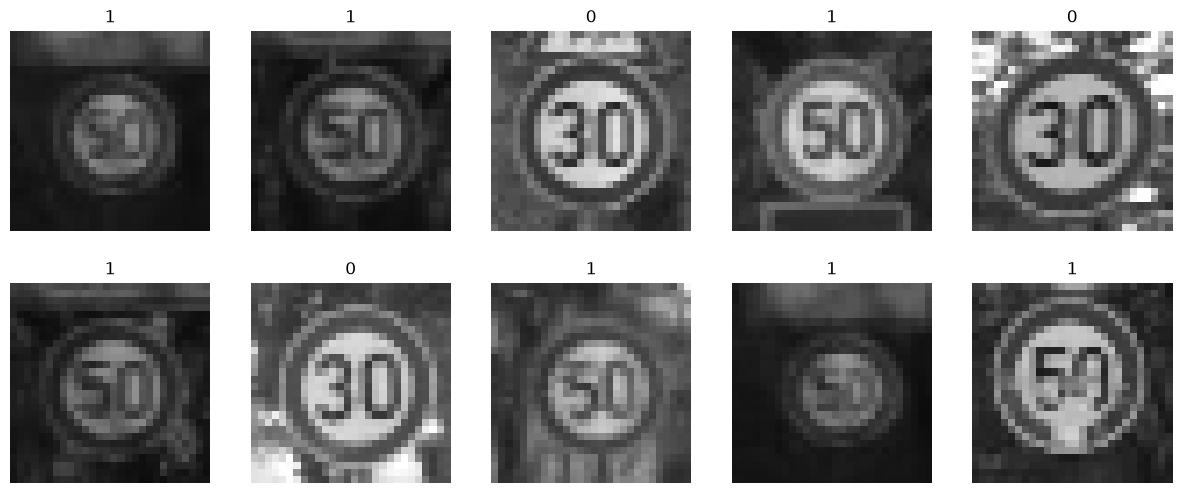

In [6]:
for cnt, idx in enumerate(np.random.randint(0, len(images), 10)):
    plt.subplot(2, 5, cnt + 1)
    plt.imshow(images[idx], cmap='gray', vmin=0, vmax=255)
    plt.title(labels[idx]), plt.axis(False)

In [7]:
import keras
from keras import Model
from keras.layers import Dense, Input

In [25]:
inputs = Input(shape=(pixels.shape[1],))
outputs = Dense(10, activation="linear")(inputs)
model = Model(inputs, outputs)

model.summary()

weights_init = model.layers[1].get_weights()[0].copy()

Model: "functional_10"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_10 (InputLayer)     │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 10)             │         7,850 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,850 (30.66 KB)

 Trainable params: 7,850 (30.66 KB)

 Non-trainable params: 0 (0.00 B)

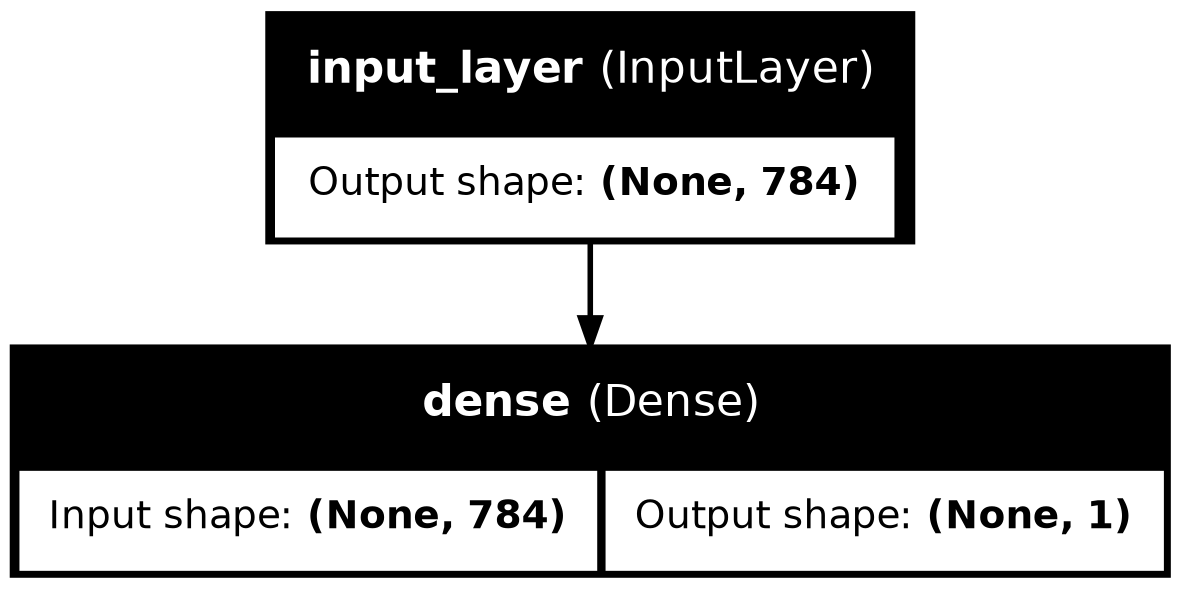

In [9]:
keras.utils.plot_model(model, to_file="model.png", show_shapes=True, show_layer_names=True)

In [11]:
model.compile(optimizer='adam', loss='mean_squared_error')

history = model.fit(pixels, labels, epochs=10, batch_size=32, verbose=2)

Epoch 1/10
140/140 - 1s - 10ms/step - loss: 0.3167
Epoch 2/10
140/140 - 1s - 9ms/step - loss: 0.2194
Epoch 3/10
140/140 - 1s - 8ms/step - loss: 0.1766
Epoch 4/10
140/140 - 1s - 10ms/step - loss: 0.1545
Epoch 5/10
140/140 - 1s - 8ms/step - loss: 0.1358
Epoch 6/10
140/140 - 1s - 8ms/step - loss: 0.1243
Epoch 7/10
140/140 - 1s - 9ms/step - loss: 0.1140
Epoch 8/10
140/140 - 1s - 8ms/step - loss: 0.1065
Epoch 9/10
140/140 - 1s - 8ms/step - loss: 0.1054
Epoch 10/10
140/140 - 1s - 9ms/step - loss: 0.0985


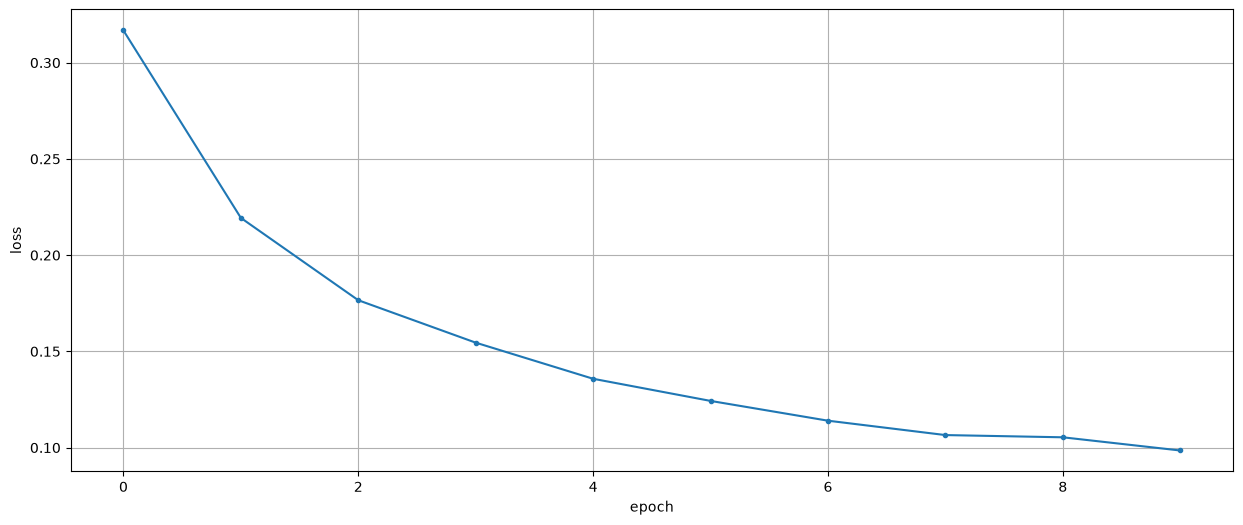

In [12]:
h = history.history
epochs = range(len(h['loss']))
plt.plot(epochs, h['loss'], '.-'), plt.grid(True)
plt.xlabel('epoch'), plt.ylabel('loss');

Bias [0.41774768]


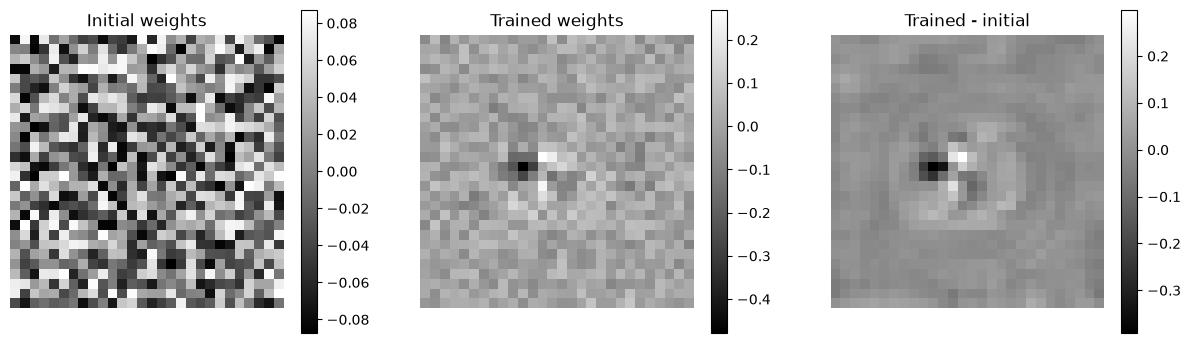

In [13]:
weights, bias = model.layers[1].get_weights()
print('Bias', bias)

for cnt, (title, w) in enumerate([('Initial weights', weights_init),
                                  ('Trained weights', weights),
                                  ('Trained - initial', weights - weights_init)]):
    plt.subplot(1, 3, cnt+1)
    plt.imshow(w.reshape(28, 28), cmap='gray'), plt.colorbar(shrink=0.7)
    plt.title(title), plt.axis(False)

Accuracy 0.9183445190156599
Number of mistakes 365


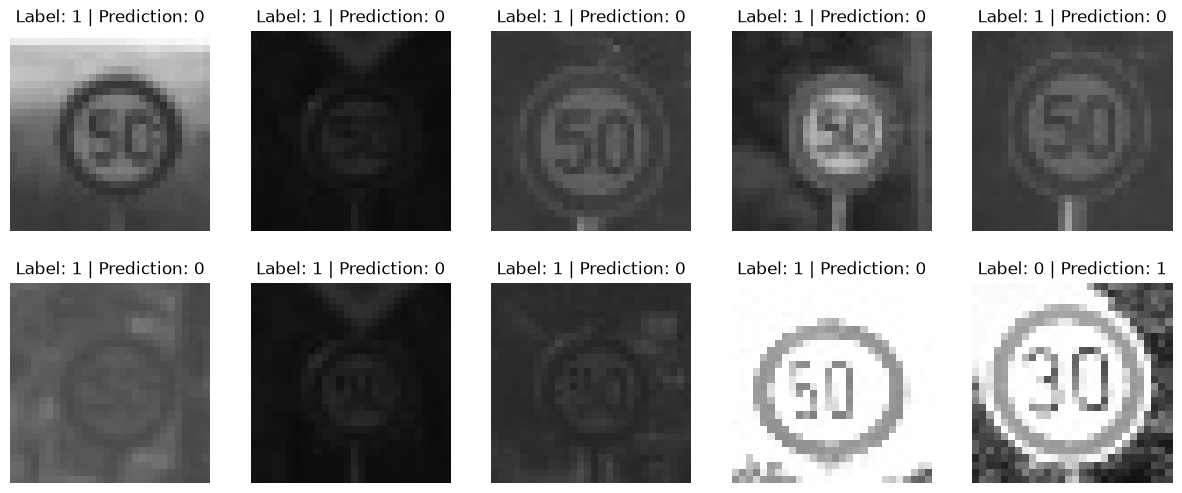

In [15]:
predictions = model.predict(pixels, verbose=0).squeeze()
predictions = (predictions > 0.5).astype(int)

correct = 0
for prediction, label in zip(predictions, labels):
    if prediction == label:
        correct = correct + 1

print('Accuracy', correct/len(labels))

for cnt, idx in enumerate(np.random.randint(0, len(images), 10)):
    plt.subplot(2,5,cnt+1), plt.imshow(images[idx], cmap='gray', vmin=0, vmax=255)
    plt.title('Label: ' + str(labels[idx]) + ' | Prediction: ' + str(predictions[idx]))
    plt.axis(False)

wrong = np.where(predictions != labels)[0]
print('Number of mistakes', len(wrong))

for cnt, idx in enumerate(wrong[:10]):
    plt.subplot(2,5,cnt+1), plt.imshow(images[idx], cmap='gray', vmin=0, vmax=255)
    plt.title('Label: ' + str(labels[idx]) + ' | Prediction: ' + str(predictions[idx]))
    plt.axis(False)

### Step 3
Make further modifications to improve the accuracy (e.g. add more neurons, more layers, etc.). What is the maximum accuracy you can achieve?

Model: "functional_12"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_12 (InputLayer)     │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 64)             │        50,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 50,305 (196.50 KB)

 Trainable params: 50,305 (196.50 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
140/140 - 2s - 16ms/step - loss: 0.2817
Epoch 2/10
140/140 - 2s - 17ms/step - loss: 0.1722
Epoch 3/10
140/140 - 3s - 20ms/step - loss: 0.1292
Epoch 4/10
140/140 - 2s - 15ms/step - loss: 0.1091
Epoch 5/10
140/140 - 2s - 16ms/step - loss: 0.0927
Epoch 6/10
140/140 - 3s - 20ms/step - loss: 0.0955
Epoch 7/10
140/140 - 2s - 15ms/step - loss: 0.0851
Epoch 8/10
140/140 - 2s - 14ms/step - loss: 0.0837
Epoch 9/10
140/140 - 2s - 15ms/step - loss: 0.0741
Epoch 10/10
140/140 - 2s - 14ms/step - loss: 0.0727


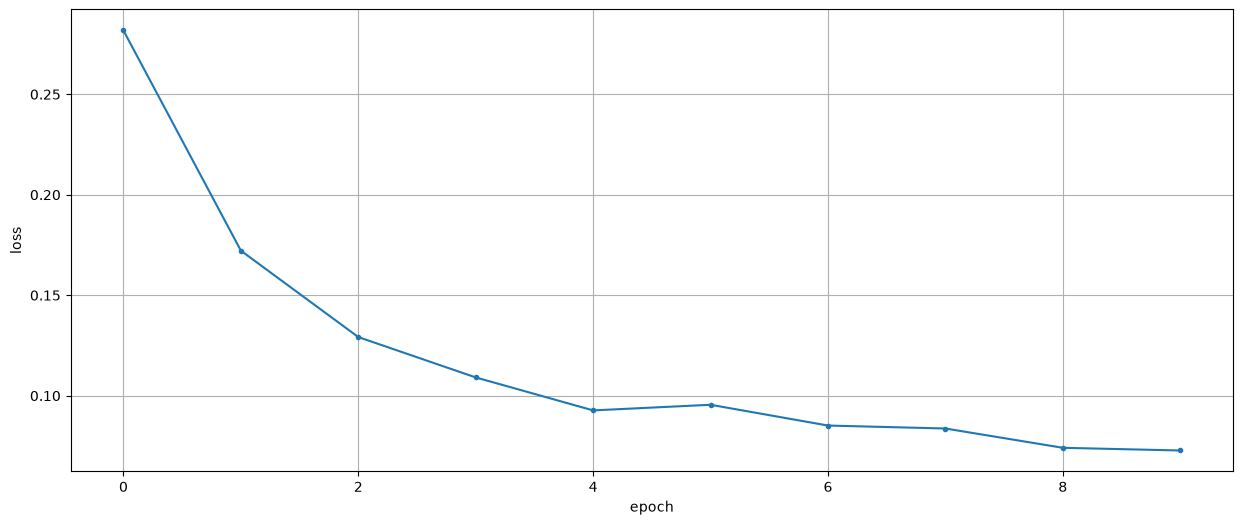

In [31]:
inputs_2 = Input(shape=(pixels.shape[1],))
hiddenLayer = Dense(64, activation="relu")(inputs_2)
outputs_2 = Dense(1, activation="linear")(hiddenLayer)
model_2 = Model(inputs_2, outputs_2)

model_2.summary()

w_init = model.layers[1].get_weights()[0].copy()
keras.utils.plot_model(model_2, to_file="model_2.png", show_shapes=True, show_layer_names=True)

model_2.compile(optimizer='adam', loss='mean_squared_error')

history_2 = model_2.fit(pixels, labels, epochs=10, batch_size=32, verbose=2)
h2 = history_2.history
epochs = range(len(h2['loss']))
plt.plot(epochs, h2['loss'], '.-'), plt.grid(True)
plt.xlabel('epoch'), plt.ylabel('loss');

In [33]:
predictions = model_2.predict(pixels, verbose=0).squeeze()
predictions = (predictions > 0.5).astype(int)

correct = 0
for prediction, label in zip(predictions, labels):
    if prediction == label:
        correct = correct + 1

print('Accuracy', correct/len(labels))

wrong = np.where(predictions != labels)[0]
print('Number of mistakes', len(wrong))


Accuracy 0.9574944071588367
Number of mistakes 190


### Bonus question
Stack two ```Dense``` layers with ```activation="linear"``` on top of each other. Do you get a better model than with one single neuron? Why (not)? Hint: have a look at the slide about the neural network and non-linearity.

In [34]:
inputs_3 = Input(shape=(pixels.shape[1],))
hiddenLayer1 = Dense(1, activation="linear")(inputs_3)
hiddenLayer2 = Dense(1, activation="linear")(hiddenLayer1)
outputs_3 = Dense(1, activation="linear")(hiddenLayer2)
model_3 = Model(inputs_3, outputs_3)

model_3.summary()

w_init = model.layers[1].get_weights()[0].copy()
keras.utils.plot_model(model_3, to_file="model_3.png", show_shapes=True, show_layer_names=True)

model_3.compile(optimizer='adam', loss='mean_squared_error')

history_3 = model_3.fit(pixels, labels, epochs=10, batch_size=32, verbose=2)
h3 = history_3.history

predictions = model_3.predict(pixels, verbose=0).squeeze()
predictions = (predictions > 0.5).astype(int)

correct = 0
for prediction, label in zip(predictions, labels):
    if prediction == label:
        correct = correct + 1

print('Accuracy', correct/len(labels))

wrong = np.where(predictions != labels)[0]
print('Number of mistakes', len(wrong))

Model: "functional_13"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_13 (InputLayer)     │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 1)              │           785 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 1)              │             2 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 1)              │             2 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 789 (3.08 KB)

 Trainable params: 789 (3.08 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
140/140 - 2s - 13ms/step - loss: 0.3546
Epoch 2/10
140/140 - 2s - 11ms/step - loss: 0.2405
Epoch 3/10
140/140 - 2s - 11ms/step - loss: 0.1832
Epoch 4/10
140/140 - 2s - 11ms/step - loss: 0.1492
Epoch 5/10
140/140 - 2s - 12ms/step - loss: 0.1319
Epoch 6/10
140/140 - 2s - 11ms/step - loss: 0.1204
Epoch 7/10
140/140 - 2s - 11ms/step - loss: 0.1186
Epoch 8/10
140/140 - 2s - 11ms/step - loss: 0.1051
Epoch 9/10
140/140 - 2s - 11ms/step - loss: 0.0998
Epoch 10/10
140/140 - 2s - 11ms/step - loss: 0.0968
Accuracy 0.9438478747203579
Number of mistakes 251


1) The experiment with different Dence layers quantity with linear activation shows that it did not perform much better. I think this happened because the network learned about the same linear relationships (several layers generally can be expressed with the same unique neuron)
2) In order to make network perform better we need to add non-linearity in some layers, like one Dense layer with RELU activation and other with Linear activasion.